# HepatoClust, notebook 2 : Classification hiérarchique (CAH)

Ce notebook applique la classification ascendante hiérarchique aux données préparées dans le notebook 1. Nous comparons 4 critères d'agrégation, nous choisissons où couper la hiérarchie, puis nous confrontons le résultat à K-Means.

**Données utilisées** : fichiers du dossier resultats/, produits par le notebook 1.
**La vraie catégorie n'est pas chargée dans ce notebook** : la CAH est construite sans elle, et la vérification se fera dans le notebook 3.

## Table des matières

0. [Imports et chargement des données](#partie0)
1. [Principe de la CAH](#s40)
2. [Calcul des 4 hiérarchies](#s41)
3. [CPCC : fidélité des dendrogrammes](#s42)
4. [Dendrogrammes](#s43)
5. [Où couper la hiérarchie](#s44)
6. [Coupe à K = 3](#s45)
7. [Effet de chaîne](#s46)
8. [Ward face à K-Means](#s47)
9. [Bilan et sauvegarde](#s48)

<a id="partie0"></a>
## Partie 0 : Imports et chargement des données

In [1]:
# Outils de base
import os
import time
import json
import warnings

# Manipulation des données
import numpy as np
import pandas as pd

# Graphiques
import matplotlib.pyplot as plt

# CAH, distances et évaluation
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Fonction commune du projet
from outils import indice_dunn, inertie

# Réglages
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)

In [2]:
with open("resultats/parametres.json", encoding="utf-8") as f:
    parametres = json.load(f)

SEED = parametres["SEED"]
K_choisi = parametres["K_choisi"]
analyses = parametres["analyses"]
parametres

{'SEED': 42,
 'K_choisi': 3,
 'analyses': ['ALB',
  'ALP',
  'ALT',
  'AST',
  'BIL',
  'CHE',
  'CHOL',
  'CREA',
  'GGT',
  'PROT'],
 'asymetriques': ['ALP', 'ALT', 'AST', 'BIL', 'CREA', 'GGT']}

In [3]:
## Données et résultats du notebook1
X_scaled = pd.read_csv("resultats/X_scaled.csv", index_col=0)
labels = pd.read_csv("resultats/labels.csv", index_col=0)
metriques = pd.read_csv("resultats/metriques.csv", index_col=0)
X_scaled.shape


(615, 10)

<a id="s40"></a>
## 4.0 Principe de la CAH

Au départ, chaque personne forme un groupe à elle seule. À chaque étape, on fusionne les deux groupes les plus proches, jusqu'à n'avoir plus qu'un seul groupe. Avec 615 personnes, il y a donc 614 fusions. Le dendrogramme dessine cet historique, et on obtient K groupes en le coupant à la bonne hauteur.

<a id="s40"></a>
## 4.0 Principe de la CAH

**Objectif** : construire une hiérarchie de groupes, comparer 4 critères d'agrégation, choisir où couper, et confronter le résultat à K-Means.

**Principe** : au départ, chaque personne forme un groupe. À chaque étape, on fusionne les deux groupes les plus proches, jusqu'à n'avoir plus qu'un seul groupe (614 fusions pour 615 personnes). Le dendrogramme dessine cet historique, et on obtient K groupes en le coupant à la bonne hauteur.

**Hypothèses et paramètres** : distance euclidienne sur les données standardisées ; critère d'agrégation (tableau ci-dessous) ; niveau de coupe, choisi avec les écarts de hauteur et la silhouette.

**Démarche** : calculer les 4 hiérarchies, mesurer leur fidélité (CPCC), lire les dendrogrammes, choisir la coupe, comparer les critères à K = 3, illustrer l'effet de chaîne, puis comparer Ward et K-Means.

**Ce qui pourrait invalider le résultat** : une fusion n'est jamais remise en cause, donc une erreur au début se propage ; les critères fondés sur la distance entre points sont sensibles aux valeurs extrêmes ; le CPCC mesure la fidélité du dendrogramme, pas la qualité des groupes ; la mémoire nécessaire grandit avec le carré du nombre de personnes.

Toute la question est de définir la distance entre deux groupes A et B. C'est le **critère d'agrégation** :

| Critère | Distance entre A et B | Comportement attendu |
|---|---|---|
| Saut minimum | $\min_{a \in A, b \in B} d(a,b)$, les deux points les plus proches | Effet de chaîne : les groupes s'allongent de proche en proche |
| Saut maximum | $\max_{a \in A, b \in B} d(a,b)$, les deux points les plus éloignés | Groupes compacts, de diamètres proches |
| Lien moyen | Moyenne de toutes les distances entre A et B | Compromis entre les deux précédents |
| Ward | Hausse de l'inertie intra-groupe causée par la fusion : $\frac{\lvert A\rvert \lvert B\rvert}{\lvert A\rvert+\lvert B\rvert} \lVert g_A - g_B \rVert^2$ | Groupes compacts de tailles proches, proche de K-Means |

Nous utilisons la distance euclidienne : les analyses sont standardisées, et Ward n'est défini que pour cette distance.

<a id="s41"></a>
## 4.1 Calcul des 4 hiérarchies

Nous construisons une hiérarchie par critère, sur les mêmes données, et nous mesurons le temps de calcul pour la comparaison finale.

In [4]:
criteres = {"Saut minimum": "single",
            "Saut maximum": "complete",
            "Lien moyen": "average",
            "Ward": "ward"}

hierarchies = {}
temps_cah = {}

for nom, methode in criteres.items():
    debut = time.time()
    hierarchies[nom] = linkage(X_scaled, method=methode, metric="euclidean")
    temps_cah[nom] = time.time() - debut

pd.Series(temps_cah, name="temps_s")

Saut minimum   0.004
Saut maximum   0.006
Lien moyen     0.005
Ward           0.006
Name: temps_s, dtype: float64

Chaque hiérarchie est un tableau de 614 lignes, une par fusion. Chaque ligne donne les deux groupes fusionnés, la distance de fusion et la taille du nouveau groupe. Voici les 5 dernières fusions de Ward, celles qui forment les grands groupes.

In [5]:
pd.DataFrame(hierarchies["Ward"][-5:],
             columns=["groupe_1", "groupe_2", "distance", "taille"])

,groupe_1,groupe_2,distance,taille
0,1152.000,1217.000,21.456,24.000
1,1212.000,1219.000,22.588,174.000
2,1218.000,1224.000,27.021,42.000
3,1223.000,1225.000,33.953,573.000
4,1226.000,1227.000,39.864,615.000


### Lecture des résultats

- Les 4 hiérarchies se calculent en moins de 0,02 seconde. La CAH garde en mémoire toutes les distances entre paires (environ 190 000 ici) : elle est rapide sur 615 personnes, mais son coût grandit avec le carré du nombre de personnes.
- Les dernières fusions de Ward donnent des groupes de 573 et 42 personnes à K = 2, et de 399, 174 et 42 personnes à K = 3.
- Le plus grand saut de distance (de 27,0 à 34,0) indique une coupe à K = 3, comme K-Means.
- Un petit groupe de 42 personnes reste isolé jusqu'à l'avant-dernière fusion. Sa composition sera vérifiée dans le notebook 3.

<a id="s42"></a>
## 4.2 CPCC : fidélité des dendrogrammes

Dans un dendrogramme, la distance entre deux personnes devient la hauteur à laquelle elles sont réunies pour la première fois (distance cophénétique). Le CPCC est la corrélation entre ces hauteurs et les vraies distances. Plus il est proche de 1, plus le dendrogramme respecte les distances réelles.

**Attention** : le CPCC mesure la fidélité du dendrogramme, pas la qualité des clusters. Un critère peut avoir un bon CPCC et donner de mauvais groupes.

In [6]:
distances = pdist(X_scaled)

cpcc = {nom: cophenet(Z, distances)[0] for nom, Z in hierarchies.items()}
pd.Series(cpcc, name="CPCC").sort_values(ascending=False)

Lien moyen     0.868
Saut minimum   0.865
Saut maximum   0.769
Ward           0.541
Name: CPCC, dtype: float64

### Lecture des résultats

- Lien moyen (0,868) et saut minimum (0,865) respectent le mieux les distances réelles : les personnes très éloignées sont réunies tout en haut, ce qui correspond à leur vraie distance.
- Ward a le CPCC le plus faible (0,541) : il fusionne selon la hausse d'inertie, qui grandit avec la taille des groupes, et non selon la distance entre points.
- Le saut minimum a presque le meilleur CPCC mais produit un effet de chaîne (voir 4.3) : un bon CPCC ne garantit pas de bons clusters. Le CPCC ne suffit donc pas pour choisir le critère.

<a id="s43"></a>
## 4.3 Dendrogrammes

Avec 615 personnes, un dendrogramme complet est illisible. Nous affichons seulement les 30 derniers groupes : un nombre entre parenthèses indique combien de personnes contient une branche repliée.

**Comment lire** : la hauteur d'une fusion est la distance entre les deux groupes réunis. Une longue branche verticale signale un groupe bien séparé des autres. Les hauteurs ne se comparent pas d'un critère à l'autre, car chaque critère mesure la distance à sa façon.

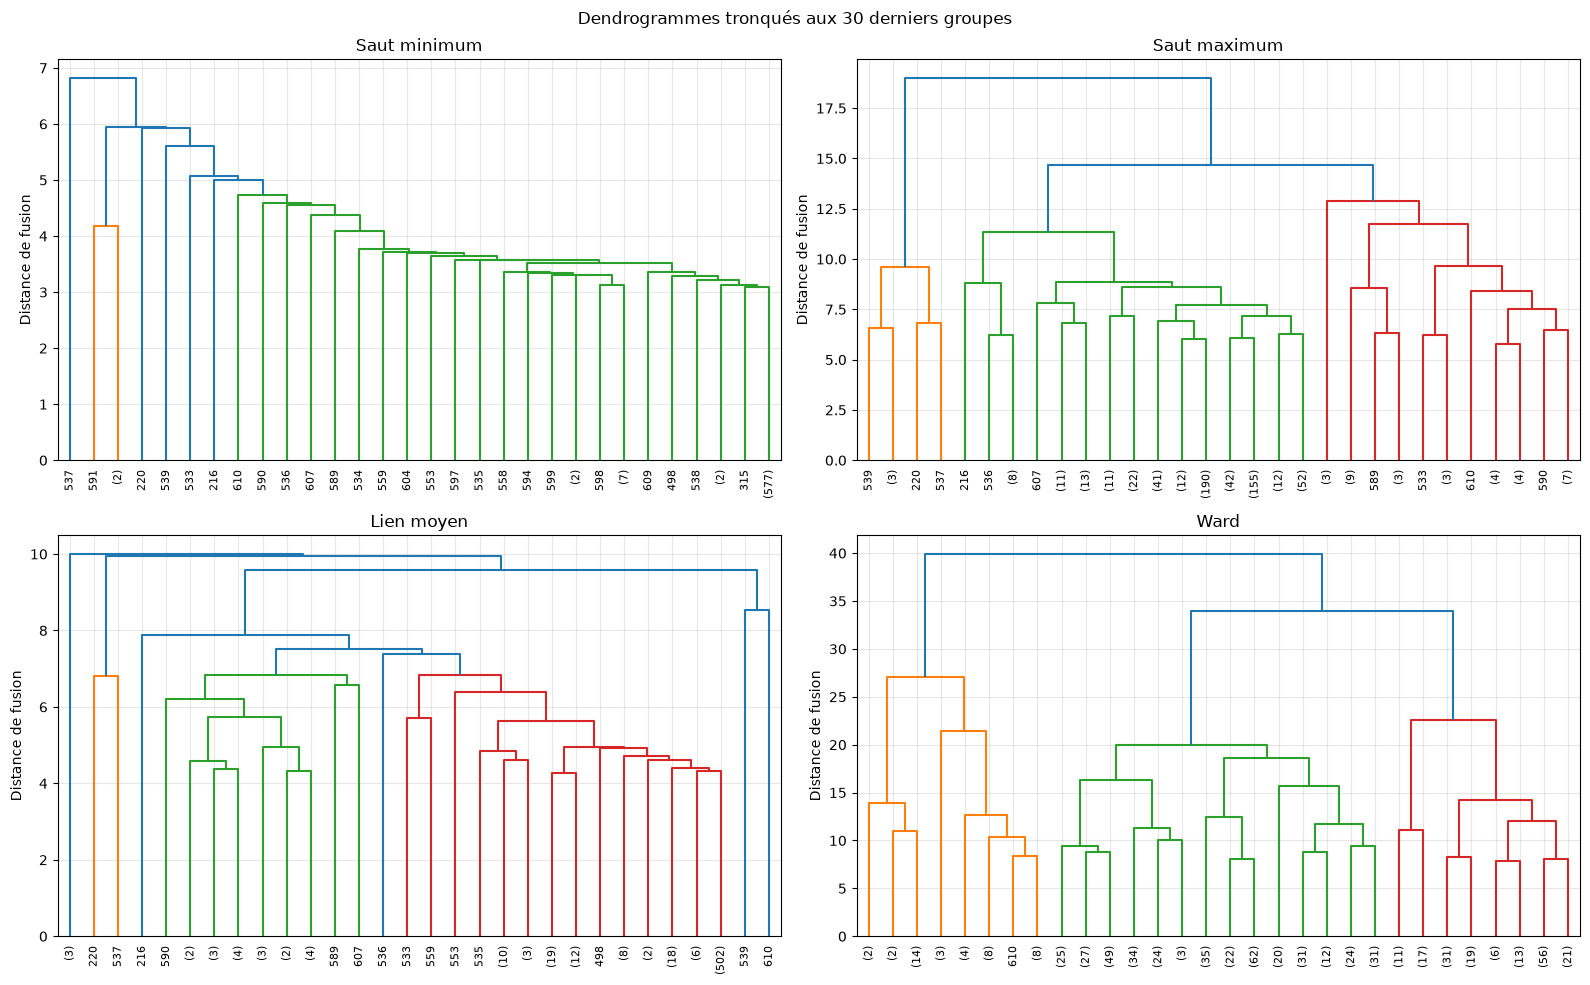

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, (nom, Z) in zip(axes.ravel(), hierarchies.items()):
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax,
               leaf_rotation=90, leaf_font_size=8)
    ax.set_title(nom)
    ax.set_ylabel("Distance de fusion")

plt.suptitle("Dendrogrammes tronqués aux 30 derniers groupes")
plt.tight_layout()
plt.savefig("figures/4_dendrogrammes.png", dpi=150)
plt.show()

### Lecture des résultats

- Saut minimum : forme en escalier, une branche de 577 personnes absorbe les autres une par une. Effet de chaîne, aucun groupe réel.
- Lien moyen : même tendance, plus faible. Les dernières fusions rattachent des groupes de 2 ou 3 personnes à un groupe d'environ 600.
- Saut maximum : de vrais groupes apparaissent, un très petit (environ 6 personnes), un grand et un d'environ 37 personnes.
- Ward : 3 groupes nets, séparés par de longues branches (42, 174 et 399 personnes). Seul critère qui donne des groupes de tailles comparables.
- Les critères fondés sur la distance entre points (minimum, moyen) isolent les personnes extrêmes. Ward et, dans une moindre mesure, le saut maximum forment de vrais groupes.

<a id="s44"></a>
## 4.4 Où couper la hiérarchie

Nous cherchons le nombre de groupes suggéré par la CAH elle-même, sans nous appuyer sur K-Means. Nous utilisons Ward, seul critère qui forme de vrais groupes (voir 4.3).

On coupe le dendrogramme là où la distance de fusion fait le plus grand saut : les groupes qu'on refuserait alors de fusionner sont nettement éloignés les uns des autres.

In [8]:
Z_ward = hierarchies["Ward"]

# Hauteur de la fusion qui fait passer de K groupes à K-1 groupes
sauts = pd.DataFrame({"K": range(2, 12),
                      "hauteur_fusion": Z_ward[::-1, 2][:10]}).set_index("K")

# Écart avec la fusion suivante : plus il est grand, plus la coupe à K groupes est nette
sauts["ecart"] = sauts["hauteur_fusion"] - sauts["hauteur_fusion"].shift(-1)
sauts

,hauteur_fusion,ecart
K,,
2,39.864,5.910
3,33.953,6.932
4,27.021,4.433
5,22.588,1.132
6,21.456,1.533
7,19.923,1.270
8,18.653,2.326
9,16.327,0.631
10,15.696,1.481


Nous complétons avec la silhouette de Ward pour K de 2 à 8, comme pour K-Means, afin d'avoir deux arguments indépendants.

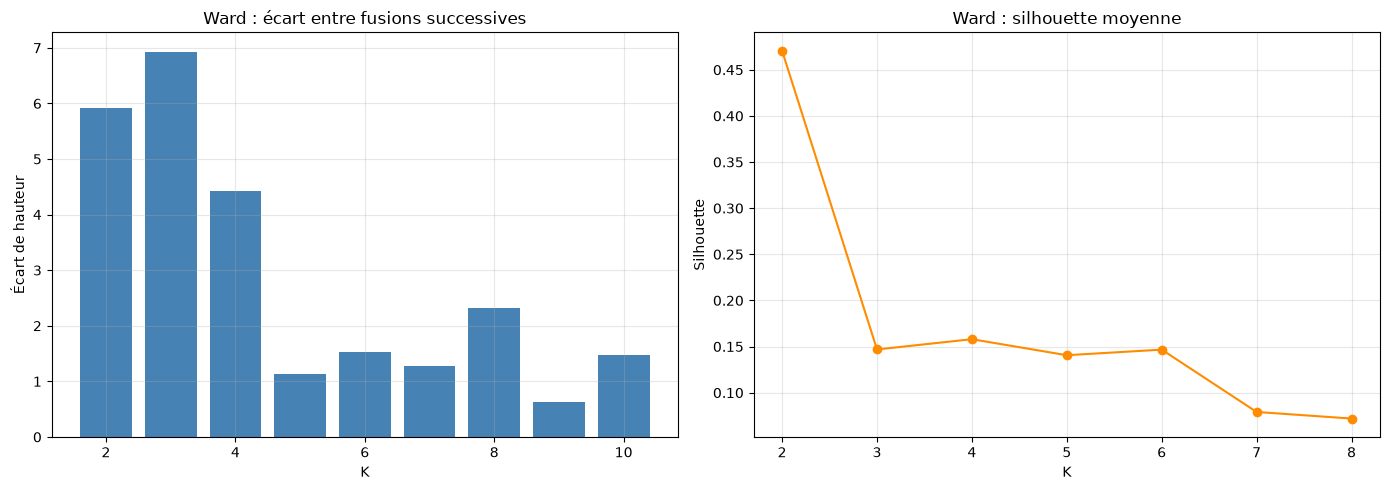

In [9]:
# Sauts et silhouettes

silhouette_ward = {k: silhouette_score(X_scaled, fcluster(Z_ward, k, criterion="maxclust"))
                   for k in range(2, 9)}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(sauts.index[:-1], sauts["ecart"].dropna(), color="steelblue")
axes[0].set_title("Ward : écart entre fusions successives")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Écart de hauteur")

axes[1].plot(list(silhouette_ward), list(silhouette_ward.values()), marker="o", color="darkorange")
axes[1].set_title("Ward : silhouette moyenne")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.savefig("figures/4_coupe_ward.png", dpi=150)
plt.show()

- Silhouette de Ward : maximale à K = 2 (0,47), puis autour de 0,15 de K = 3 à 6. À K = 2, Ward isole le groupe atypique de 42 personnes, très éloigné du reste, ce qui fait monter la silhouette. À K = 3, il coupe aussi la masse principale en deux groupes qui se chevauchent.
- Les deux critères ne s'accordent donc pas : l'écart de hauteur indique K = 3, la silhouette indique K = 2. La séparation la plus nette est « profils normaux contre profils atypiques ». La coupe de la masse principale est plus fragile.
- Nous gardons K = 3 pour comparer les méthodes dans les mêmes conditions, et nous examinerons aussi K = 2 face à la vraie catégorie dans le notebook 3.

<a id="s44"></a>
## 4.4 Où couper la hiérarchie

Nous cherchons le nombre de groupes suggéré par chaque hiérarchie elle-même, sans nous appuyer sur K-Means. La règle est la même pour les 4 critères : on coupe là où la distance de fusion fait le plus grand saut, et on regarde la taille des groupes obtenus.

Les écarts ne se comparent qu'à l'intérieur d'un même critère, car chaque critère mesure la distance à sa façon.

In [10]:
coupes = []

for nom, Z in hierarchies.items():
    hauteurs = Z[::-1, 2][:11]                 # 11 dernières fusions, de la plus haute à la plus basse
    ecarts = hauteurs[:-1] - hauteurs[1:]      # écart pour K = 2 à 11
    k_suggere = int(np.argmax(ecarts)) + 2
    tailles = np.bincount(fcluster(Z, k_suggere, criterion="maxclust"))[1:]
    coupes.append({"critere": nom,
                   "K_suggere": k_suggere,
                   "ecart_max": ecarts.max(),
                   "tailles": sorted(tailles, reverse=True)})

pd.DataFrame(coupes).set_index("critere")

,K_suggere,ecart_max,tailles
critere,,,
Saut minimum,2,0.863,"[614, 1]"
Saut maximum,2,4.321,"[609, 6]"
Lien moyen,4,1.037,"[608, 3, 2, 2]"
Ward,3,6.932,"[399, 174, 42]"


### Lecture des résultats

| Critère | Coupe suggérée | Tailles |
|---|---|---|
| Saut minimum | K = 2 | 614 et 1 |
| Saut maximum | K = 2 | 609 et 6 |
| Lien moyen | K = 4 | 608, 3, 2 et 2 |
| Ward | K = 3 | 399, 174 et 42 |

- Pour le saut minimum, le saut maximum et le lien moyen, le plus grand saut isole seulement 1 à 7 personnes extrêmes : ces coupes ne forment pas de vrais groupes.
- Ward est le seul critère dont la coupe naturelle produit des groupes de tailles significatives. Il suggère K = 3, comme K-Means.
- Les critères fondés sur la distance entre points sont très sensibles aux valeurs extrêmes, que la préparation a réduites sans les supprimer.

In [11]:
Z_ward = hierarchies["Ward"]

# Hauteur de la fusion qui fait passer de K groupes à K-1 groupes
sauts = pd.DataFrame({"K": range(2, 12),
                      "hauteur_fusion": Z_ward[::-1, 2][:10]}).set_index("K")

# Écart avec la fusion suivante : plus il est grand, plus la coupe à K groupes est nette
sauts["ecart"] = sauts["hauteur_fusion"] - sauts["hauteur_fusion"].shift(-1)
sauts.T

K,2,3,4,5,6,7,8,9,10,11
hauteur_fusion,39.864,33.953,27.021,22.588,21.456,19.923,18.653,16.327,15.696,14.215
ecart,5.910,6.932,4.433,1.132,1.533,1.270,2.326,0.631,1.481,NaN



<a id="s45"></a>
## 4.5 Coupe à K = 3 pour les 4 critères

Pour comparer les critères dans les mêmes conditions, nous coupons les 4 hiérarchies à K = 3, le nombre retenu par K-Means et par Ward. Pour chaque critère, nous mesurons la taille des groupes, la silhouette et l'indice de Dunn, et nous rappelons le CPCC et le temps de calcul.

In [12]:
labels_cah = {}
resultats_cah = []

for nom, Z in hierarchies.items():
    lab = fcluster(Z, K_choisi, criterion="maxclust")
    labels_cah[nom] = lab
    resultats_cah.append({"critere": nom,
                          "tailles": sorted(np.bincount(lab)[1:], reverse=True),
                          "silhouette": silhouette_score(X_scaled, lab),
                          "dunn": indice_dunn(X_scaled.values, lab),
                          "CPCC": cpcc[nom],
                          "temps_s": temps_cah[nom]})

resultats_cah = pd.DataFrame(resultats_cah).set_index("critere")
resultats_cah

,tailles,silhouette,dunn,CPCC,temps_s
critere,,,,,
Saut minimum,"[611, 3, 1]",0.592,0.406,0.865,0.004
Saut maximum,"[572, 37, 6]",0.456,0.113,0.769,0.006
Lien moyen,"[610, 3, 2]",0.578,0.404,0.868,0.005
Ward,"[399, 174, 42]",0.147,0.051,0.541,0.006


- Le saut minimum et le lien moyen ont les meilleurs indices, mais ils isolent seulement 4 ou 5 personnes : les indices récompensent la mise à l'écart des valeurs extrêmes, pas la formation de groupes utiles.
- Un indice seul ne suffit donc pas pour choisir une méthode : il faut toujours regarder la taille des groupes.
- Le saut maximum forme un groupe de 37 personnes, et Ward un groupe de 42 : deux candidats à confronter à la vraie catégorie dans le notebook 3.
- Ward fait un peu moins bien que K-Means (silhouette 0,147 contre 0,165) : K-Means optimise directement l'inertie et corrige ses affectations, alors que Ward ne peut jamais défaire une fusion.

<a id="s46"></a>
## 4.6 Effet de chaîne

Avec le saut minimum, deux groupes sont fusionnés dès qu'une seule paire de points est proche. Des personnes intermédiaires servent alors de « ponts » : de proche en proche, des régions différentes finissent dans un même groupe géant. Seules les personnes très isolées restent à part.

Nous comparons le saut minimum et Ward sur la même projection en 2 dimensions (ACP, 47 % de l'information, utilisée seulement pour dessiner).

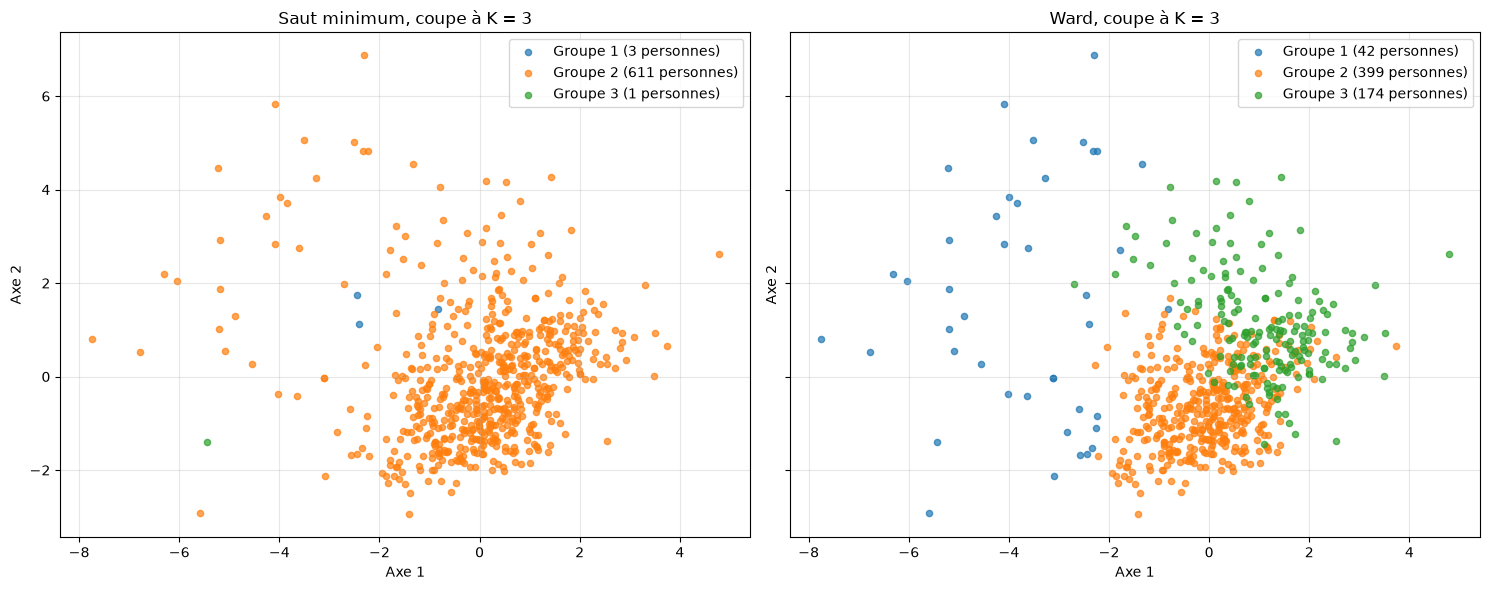

In [13]:
X_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

for ax, nom in zip(axes, ["Saut minimum", "Ward"]):
    lab = labels_cah[nom]
    for c in np.unique(lab):
        masque = lab == c
        ax.scatter(X_2d[masque, 0], X_2d[masque, 1], s=20, alpha=0.7,
                   label=f"Groupe {c} ({masque.sum()} personnes)")
    ax.set_title(f"{nom}, coupe à K = 3")
    ax.set_xlabel("Axe 1")
    ax.set_ylabel("Axe 2")
    ax.legend()

plt.tight_layout()
plt.savefig("figures/4_effet_chaine.png", dpi=150)
plt.show()

### Lecture des résultats

- Saut minimum : presque tout le nuage forme un seul groupe, y compris la queue de points très éloignés à gauche, rattachée de proche en proche. C'est l'effet de chaîne.
- Les 4 personnes isolées par le saut minimum ne sont pas les plus éloignées sur ce dessin : elles le sont dans les 10 dimensions, sur des axes que l'ACP ne montre pas.
- Ward : le groupe de 42 personnes correspond à la queue dispersée à gauche (profils les plus atypiques), celui de 399 au cœur dense du nuage, celui de 174 à la zone en haut à droite.
- Les groupes de 399 et 174 se chevauchent sur la projection, ce qui est cohérent avec la silhouette faible de Ward (0,147).

<a id="s47"></a>
## 4.7 Ward face à K-Means

Ward et K-Means cherchent tous les deux des groupes compacts, avec une inertie faible. Nous vérifions s'ils trouvent les mêmes groupes. Les numéros des groupes sont arbitraires : on regarde si chaque groupe de K-Means correspond surtout à un groupe de Ward.

In [20]:
comparaison = pd.crosstab(labels["kmeans"].values, labels_cah["Ward"],
                          rownames=["K-Means"], colnames=["Ward"])
comparaison

Ward,1,2,3
K-Means,,,
0,0,97,165
1,15,301,6
2,27,1,3


In [22]:
# Chaque groupe K-Means est associé à son groupe Ward majoritaire
accord = comparaison.max(axis=1).sum() / comparaison.values.sum() * 100
print(round(accord, 1))

80.2


### Lecture des résultats

| K-Means | Taille | Correspondance dans Ward |
|---|---|---|
| Groupe 2 | 31 | 27 dans le groupe Ward de 42 : petit groupe atypique |
| Groupe 1 | 322 | 301 dans le groupe Ward de 399 : cœur du nuage |
| Groupe 0 | 262 | 165 dans le groupe Ward de 174, 97 dans celui de 399 : groupe intermédiaire |

- Les deux méthodes classent 80,2 % des personnes de la même façon (493 sur 615). Elles fonctionnent pourtant très différemment : la structure en 3 groupes est donc robuste.
- Le petit groupe atypique est le plus stable : 27 personnes sont isolées par les deux méthodes.
- Les désaccords se concentrent à la frontière entre les deux grands groupes (97 personnes), qui se chevauchent : cela explique les silhouettes faibles.

<a id="s48"></a>
## 4.8 Bilan et sauvegarde

Nous ajoutons les clusters des 4 critères au fichier labels.csv, et leurs métriques au fichier metriques.csv, pour la comparaison finale du notebook 3.

In [17]:
# Contrôle : notre fonction doit retrouver l'inertie calculée par K-Means
inertie(X_scaled, labels["kmeans"]), metriques.loc["K-Means", "inertie"]

(np.float64(4545.2739854778165), np.float64(4545.273985477817))

Notre fonction retrouve exactement l'inertie de K-Means (4545,27) : l'inertie de la CAH est calculée de la même façon, et la comparaison est équitable.

In [18]:
# Sauvegarde des clusters

for nom, methode in criteres.items():
    labels[f"cah_{methode}"] = labels_cah[nom]

labels.to_csv("resultats/labels.csv")
labels.head()

,kmeans,cah_single,cah_complete,cah_average,cah_ward
1,1,2,2,3,2
2,1,2,2,3,2
3,0,2,2,3,2
4,0,2,2,3,2
5,1,2,2,3,2


In [19]:
# Sauvegarde des metriques

lignes_cah = pd.DataFrame({"K": K_choisi,
                           "inertie": [inertie(X_scaled, labels_cah[nom]) for nom in criteres],
                           "silhouette": resultats_cah["silhouette"].values,
                           "dunn": resultats_cah["dunn"].values,
                           "CPCC": resultats_cah["CPCC"].values,
                           "temps_s": resultats_cah["temps_s"].values},
                          index=[f"CAH {nom}" for nom in criteres])
lignes_cah.index.name = "methode"

# On retire d'éventuelles anciennes lignes CAH pour pouvoir réexécuter sans doublons
metriques = pd.concat([metriques.drop(lignes_cah.index, errors="ignore"), lignes_cah])
metriques.to_csv("resultats/metriques.csv")
metriques

,K,inertie,silhouette,dunn,temps_s,CPCC
methode,,,,,,
K-Means,3,4545.274,0.165,0.058,0.121,NaN
CAH Saut minimum,3,5772.645,0.592,0.406,0.004,0.865
CAH Saut maximum,3,5147.192,0.456,0.113,0.006,0.769
CAH Lien moyen,3,5730.736,0.578,0.404,0.005,0.868
CAH Ward,3,4779.017,0.147,0.051,0.006,0.541


### Lecture des résultats

- L'inertie classe les méthodes comme l'analyse des tailles : K-Means (4545), Ward (4779), saut maximum (5147), lien moyen (5731), saut minimum (5773). Les critères qui isolent quelques personnes laissent un groupe géant très étalé.
- K-Means a l'inertie la plus faible, car c'est ce qu'il optimise. Ward n'est que 5 % au-dessus, sans jamais pouvoir défaire une fusion.
- Les temps sont tous inférieurs à 0,02 seconde et varient d'une exécution à l'autre : ils ne permettent pas de départager les critères.

### Bilan de la CAH

- Les 4 critères ont été calculés sur les mêmes données standardisées, avec la distance euclidienne.
- Le CPCC favorise le lien moyen (0,868) et le saut minimum (0,865), mais ces critères isolent seulement quelques personnes extrêmes, avec un effet de chaîne pour le saut minimum.
- La silhouette et l'indice de Dunn favorisent aussi ces mauvais découpages : un indice seul ne suffit pas, il faut regarder la taille des groupes. Seule l'inertie est cohérente avec cette analyse.
- Ward est le seul critère qui forme 3 vrais groupes (399, 174 et 42). Il suggère K = 3 de lui-même, comme K-Means mais sa silhouette préfère K = 2.
- Ward et K-Means s'accordent sur 80,2 % des personnes, et le petit groupe atypique est commun aux deux méthodes (27 personnes).
- **Critère retenu : Ward.** Le saut maximum, qui forme un groupe de 37 personnes, sera aussi confronté à la vraie catégorie dans le notebook 3.